# Monitor for the super-long run (`long_run.py`)
Re-run all cells at any time while the run is going: they only read `long_runs/*_log.jsonl`.

What to look for: a **phase change** is a sudden rise in the linear regime probe / R²(regime indicator) /
MLP probe, typically together with a jump in the number of canonical correlations above θ = 0.867 (the regime
indicator's predictability) or a step in the prediction loss.

In [5]:
import json, glob, os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "figure.dpi": 110, "font.size": 9})
pal = {"shared": "#2a78d6", "separate": "#eb6834"}
runs = {}
for f in sorted(glob.glob("long_runs/*_log.jsonl")):
    print(f"Loading {f}...")
    recs = [json.loads(l) for l in open(f)]
    tag = os.path.basename(f).replace("_log.jsonl", "")
    runs[tag] = dict(loss=pd.DataFrame([r for r in recs if r["kind"] == "loss"]),
                     ev=pd.DataFrame([r for r in recs if r["kind"] == "eval"]))
for tag, r in runs.items():
    ev = r["ev"]
    print(f"{tag}: {int(r['loss'].step.max()) if len(r['loss']) else 0} steps logged; last eval at step "
          f"{int(ev.step.max()) if len(ev) else 0}; latest linear probe {ev.lin_probe.iloc[-1]:.3f}" if len(ev) else tag)

Loading long_runs/separate_lam0.5_lr0.0003_fresh_gap1_scratch_log.jsonl...


JSONDecodeError: Extra data: line 1 column 132 (char 131)

/var/folders/27/dh5vcb994tl8b5yj9lprntpm0000gq/T/ipykernel_9182/59860276.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a.set_title(t); a.set_xlabel("step of the long run"); a.legend(frameon=False, fontsize=7)


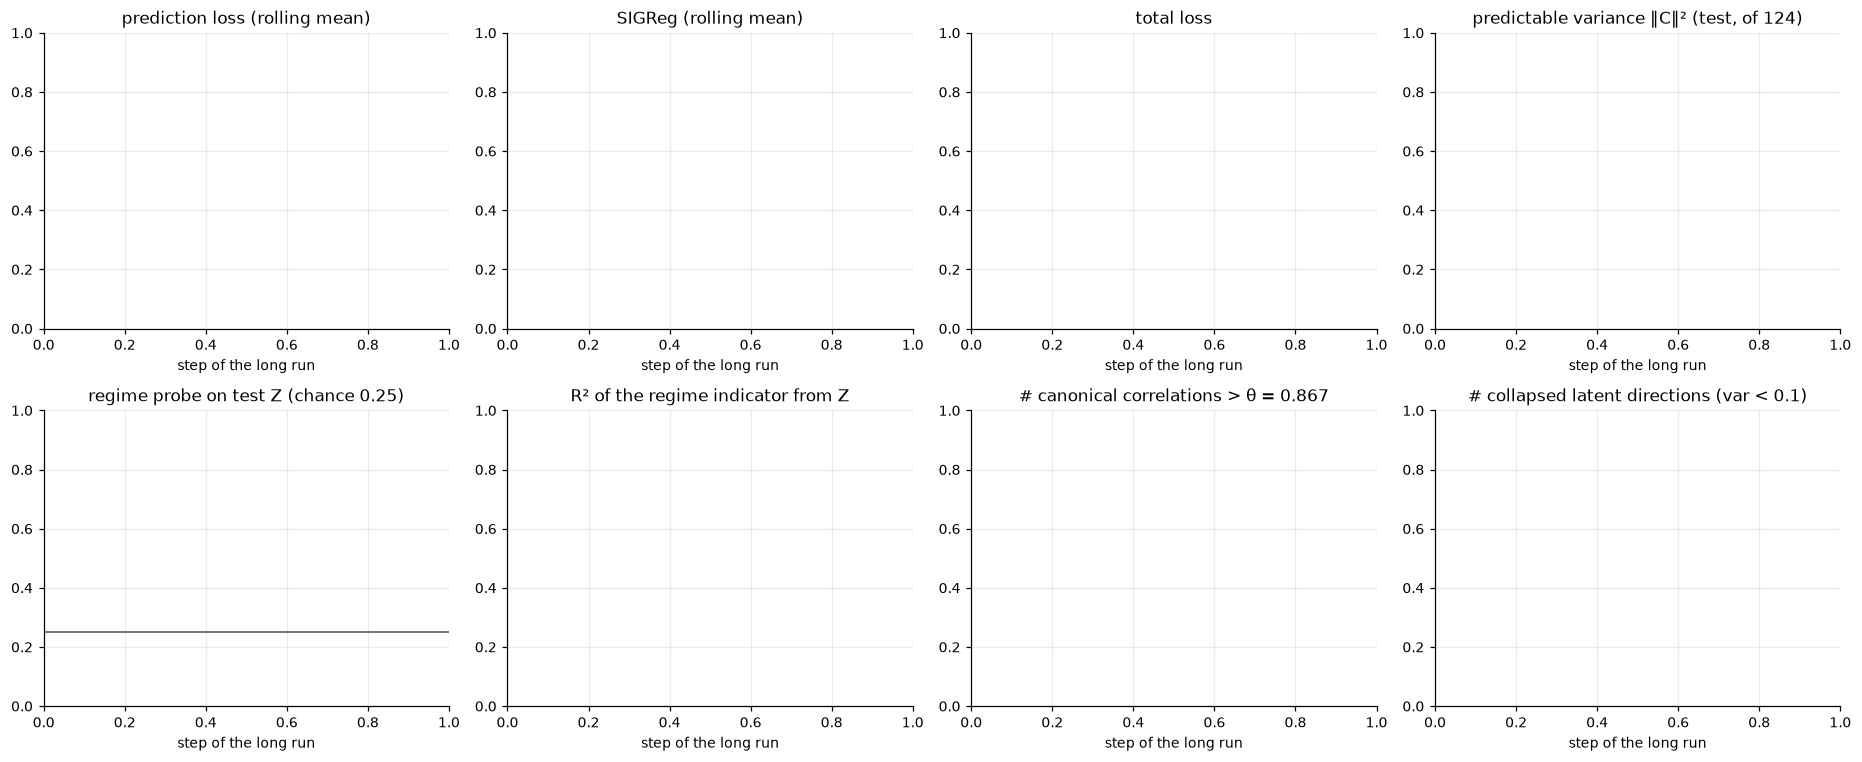

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
for tag, r in runs.items():
    col = pal["shared" if tag.startswith("shared") else "separate"]
    lo, ev = r["loss"], r["ev"]
    if len(lo):
        sm = lambda s: s.rolling(10, min_periods=1).mean()
        axs[0, 0].plot(lo.step, sm(lo.pred), color=col, lw=1.2, label=tag)
        axs[0, 1].plot(lo.step, sm(lo.sigreg), color=col, lw=1.2, label=tag)
        axs[0, 2].plot(lo.step, sm(lo.total), color=col, lw=1.2, label=tag)
    if len(ev):
        axs[0, 3].plot(ev.step, ev.score, "o-", ms=3, color=col, label=tag)
        axs[1, 0].plot(ev.step, ev.lin_probe, "o-", ms=3, color=col, label=f"{tag} linear")
        if "mlp_probe" in ev:
            d = ev.dropna(subset=["mlp_probe"]); axs[1, 0].plot(d.step, d.mlp_probe, "s--", ms=5, color=col, label=f"{tag} MLP")
        axs[1, 1].plot(ev.step, ev.r2_regime, "o-", ms=3, color=col, label=tag)
        axs[1, 2].plot(ev.step, ev.canon_above_theta, "o-", ms=3, color=col, label=tag)
        axs[1, 3].plot(ev.step, ev.dirs_var_below_0_1, "o-", ms=3, color=col, label=tag)
axs[1, 0].axhline(0.25, color="#52514e", lw=1)
titles = ["prediction loss (rolling mean)", "SIGReg (rolling mean)", "total loss", "predictable variance ‖C‖² (test, of 124)",
          "regime probe on test Z (chance 0.25)", "R² of the regime indicator from Z", "# canonical correlations > θ = 0.867",
          "# collapsed latent directions (var < 0.1)"]
for a, t in zip(axs.flat, titles):
    a.set_title(t); a.set_xlabel("step of the long run"); a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
# what the latent spends its dimensions on (every 10 000 steps)
for tag, r in runs.items():
    ev = r["ev"]
    cols = [c for c in ev.columns if c.startswith("r2 ")]
    if cols:
        d = ev.dropna(subset=["mlp_probe"])[["step", "mlp_probe"] + cols].set_index("step")
        d.columns = [c.replace("r2 ", "R² ") for c in d.columns]
        print(tag); display(d.round(3))

separate_lam0.5_lr0.0003_fresh_gap1_scratch


,mlp_probe,R² regime indicator,R² regime state x,R² g = x·1[S=k],R² state energy per plane,R² slow factors,R² slow factors²,R² oscillators,R² log-volatility,R² gain drift,R² distractors
step,,,,,,,,,,,
0,0.442,0.132,0.024,0.004,0.251,0.893,0.313,0.193,0.197,0.720,0.275
10000,0.958,0.832,0.622,0.354,0.459,0.958,0.838,0.919,0.747,0.970,0.060
20000,0.953,0.846,0.580,0.356,0.448,0.962,0.839,0.929,0.864,0.974,0.033
30000,0.973,0.872,0.592,0.387,0.442,0.961,0.837,0.931,0.871,0.975,0.030


separate_lam0.5_lr0.0003_fresh


,mlp_probe,R² regime indicator,R² regime state x,R² g = x·1[S=k],R² state energy per plane,R² slow factors,R² slow factors²,R² oscillators,R² log-volatility,R² gain drift,R² distractors
step,,,,,,,,,,,
0,0.266,0.0,0.483,0.112,0.057,0.945,0.811,0.943,0.0,0.963,0.0
10000,0.263,0.0,0.481,0.109,0.067,0.948,0.824,0.951,0.0,0.963,0.0
20000,0.255,0.0,0.505,0.114,0.093,0.943,0.816,0.953,0.0,0.964,0.0


separate_lam0.5_lr0.0003


,mlp_probe,R² regime indicator,R² regime state x,R² g = x·1[S=k],R² state energy per plane,R² slow factors,R² slow factors²,R² oscillators,R² log-volatility,R² gain drift,R² distractors
step,,,,,,,,,,,
0,0.266,0.0,0.483,0.112,0.057,0.945,0.811,0.943,0.0,0.963,0.0


shared_lam0.5_lr0.0003


,mlp_probe,R² regime indicator,R² regime state x,R² g = x·1[S=k],R² state energy per plane,R² slow factors,R² slow factors²,R² oscillators,R² log-volatility,R² gain drift,R² distractors
step,,,,,,,,,,,
0,0.297,0.000,0.215,0.103,0.0,0.952,0.798,0.879,0.877,0.923,0.0
10000,0.313,0.000,0.220,0.106,0.0,0.948,0.795,0.872,0.872,0.914,0.0
20000,0.327,0.000,0.231,0.116,0.0,0.941,0.792,0.868,0.864,0.886,0.0
30000,0.479,0.000,0.250,0.138,0.0,0.927,0.744,0.862,0.845,0.845,0.0
40000,0.568,0.000,0.267,0.145,0.0,0.899,0.713,0.858,0.844,0.816,0.0
50000,0.602,0.032,0.266,0.144,0.0,0.795,0.682,0.853,0.833,0.708,0.0
60000,0.609,0.056,0.268,0.142,0.0,0.599,0.697,0.850,0.837,0.676,0.0
70000,0.628,0.081,0.269,0.143,0.0,0.560,0.703,0.852,0.836,0.613,0.0
80000,0.630,0.109,0.270,0.148,0.0,0.547,0.687,0.851,0.811,0.589,0.0
